In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures, SplineTransformer
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import root_mean_squared_error

import os
os.chdir('/Users/lior/DS6021/DS6021_F26/data')
auto = pd.read_csv("Auto.csv", na_values="?").dropna().reset_index(drop=True)
print(auto.shape)
#claude was used to clean code in some sections

(392, 9)


In [4]:
auto["cyl_rollup"] = np.where(auto["cylinders"] < 6, "<6", np.where(auto["cylinders"] == 6, "6", "8"))
print(auto["cyl_rollup"].value_counts())

cyl_rollup
<6    206
8     103
6      83
Name: count, dtype: int64


In [5]:
numA = ["displacement", "weight", "year"]
catB = ["cyl_rollup", "origin"]
XA, XB = auto[numA], auto[numA + catB]
def make_model(cat):
    if cat:
        pre = make_column_transformer((StandardScaler(), numA),
                                      (OneHotEncoder(drop="first"), catB))
    else:
        pre = make_column_transformer((StandardScaler(), numA))
    return make_pipeline(pre, LinearRegression())
models = {"Model A": (make_model(False), XA), "Model B": (make_model(True), XB)}

In [ ]:
#1a
rows = []
y = auto["mpg"]
for name, (m, X) in models.items():
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
    m.fit(Xtr, ytr)
    rows.append({"Model": name, "Train RMSE": root_mean_squared_error(ytr, m.predict(Xtr)),
                 "Test RMSE": root_mean_squared_error(yte, m.predict(Xte))})
split_tbl = pd.DataFrame(rows).set_index("Model"); print(split_tbl.round(3))

         Train RMSE  Test RMSE
Model                         
Model A       3.460      3.261
Model B       3.226      3.089


1b

Model B is better because it has a lower train and test RMSE, so it helps on not only training data but also unseen data.

In [8]:
#2a

def cv_rmse(m, X, k, seed=42):
    mse = -cross_val_score(m, X, y, cv=KFold(k, shuffle=True, random_state=seed),
                           scoring="neg_mean_squared_error")
    return np.sqrt(mse.mean())
cmp = split_tbl[["Test RMSE"]].rename(columns={"Test RMSE": "Single split"})
cmp["5-fold"] = [cv_rmse(m, X, 5) for m, X in models.values()]
cmp["10-fold"] = [cv_rmse(m, X, 10) for m, X in models.values()]
print(cmp.round(3))

         Single split  5-fold  10-fold
Model                                 
Model A         3.261   3.445    3.441
Model B         3.089   3.257    3.262


the 5 fold and 10 fold results are very similar for both model a and model b. thesingle split gave lower overall results for both models, meaning its more optimistic overall and is more reliable.

2c

Model B is still better because the CV RMSE is slightly lower than Model A's for both 5 and 10 folds.

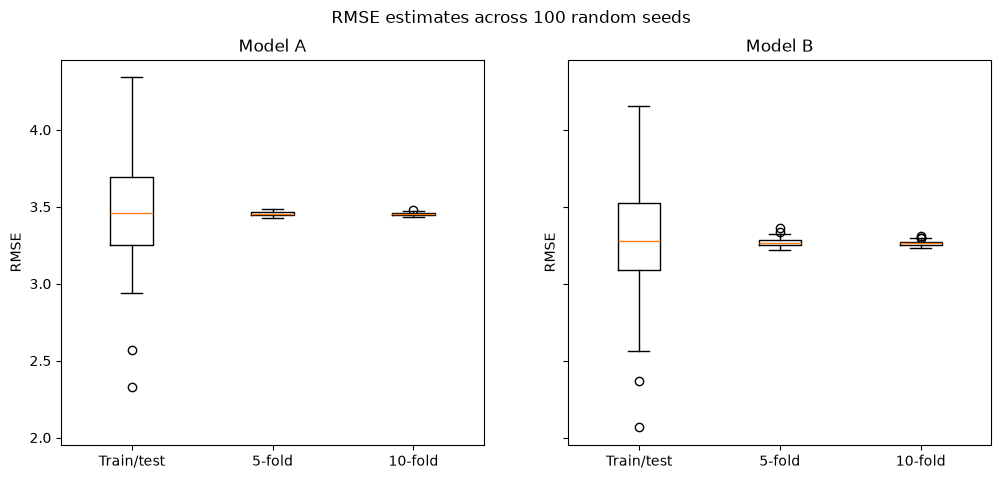

                     mean    std
model   method                  
Model A 10-fold     3.454  0.009
        5-fold      3.456  0.014
        Train/test  3.472  0.344
Model B 10-fold     3.264  0.014
        5-fold      3.269  0.024
        Train/test  3.292  0.349


In [ ]:
#3a
rows = []
for seed in range(100):
    for name, (m, X) in models.items():
        Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
        m.fit(Xtr, ytr)
        rows += [{"model":name,"method": "Train/test", "rmse": root_mean_squared_error(yte, m.predict(Xte))},
                 {"model":name,"method": "5-fold", "rmse": cv_rmse(m, X, 5, seed)},
                 {"model":name,"method": "10-fold", "rmse": cv_rmse(m, X, 10, seed)}]
by_seed = pd.DataFrame(rows)
order = ["Train/test", "5-fold", "10-fold"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, name in zip(axes, models):
    d = by_seed[by_seed.model == name]
    ax.boxplot([d.loc[d.method == m, "rmse"] for m in order], tick_labels=order)
    ax.set(title=name, ylabel="RMSE")
fig.suptitle("RMSE estimates across 100 random seeds");
plt.show()
print(by_seed.groupby(["model", "method"])["rmse"].agg(["mean", "std"]).round(3))

I would choose Model B since the overall averages are lower than Model A and the boxes for B are lower than the boxes for A in every method.The train/test values vary depending on the seed, but seem to be stable for the 5 fold and 10 fold values.

3b

In my opinion, i think that it is worth it because the RMSE gain that you get across the seeds is consistent enough for it to be reliable and is still bigger than the CV noise with it only needing an extra couple of dummy variables.